In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Load the data (change the path if needed)
df = pd.read_excel("C:/Users/hp/Downloads/ML_Fitting_Data.xlsx")
df.head()
print(df.shape)
print(df.head())
print(df["Churn"].value_counts(normalize=True))
## (800, 13), with 60.75% not churned and 39.25% churned

(800, 13)
   Age  Tenure_Months  Monthly_Charge  Support_Calls  Noise_1  Noise_2  \
0   25             51           20.00              2   -1.328   -1.261   
1   48             61           30.92              3    1.977   -0.216   
2   22             30           48.34              2   -0.605    0.101   
3   51             27           53.85              2   -0.568    0.229   
4   50             51           56.83              0   -0.066    0.470   

   Noise_3  Noise_4  Noise_5  Noise_6  Noise_7  Noise_8  Churn  
0    0.837   -0.815   -1.864    1.664    0.731   -0.375      0  
1   -0.435    1.290    0.099   -0.749    1.113    1.310      0  
2   -0.249    0.765   -0.794   -0.263    0.984    0.143      0  
3   -1.130   -0.693   -0.186    0.351    1.570    1.029      0  
4   -0.648    0.040   -1.685    0.487   -0.170    0.302      0  
Churn
0    0.6075
1    0.3925
Name: proportion, dtype: float64


In [28]:
## Step 2: Split into training and test data
## The gap between training and test scores is how we detect both problems
X = df.drop(columns="Churn")
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (560, 12)  Test: (240, 12)


In [17]:
# PROBLEM 1: Underfitting
#The model is too simple (a tree with only 1 split), so it cannot learn the real pattern.
under = DecisionTreeClassifier(max_depth=1, random_state=42)
under.fit(X_train, y_train)
tr = accuracy_score(y_train, under.predict(X_train))
te = accuracy_score(y_test, under.predict(X_test))
print(f"UNDERFITTING -> Train: {tr:.3f} | Test: {te:.3f}")
## both scores are low and close together. 
##The model is weak on the training data itself, which is the sign of underfitting (high bias). 
## A stronger model reaches about 0.81 on this data.

UNDERFITTING -> Train: 0.745 | Test: 0.767


In [18]:
## PROBLEM 2: Overfitting
##The model is too complex (no depth limit), so it memorizes the training data, including the noise columns
over = DecisionTreeClassifier(random_state=42)   # no limits
over.fit(X_train, y_train)
tr = accuracy_score(y_train, over.predict(X_train))
te = accuracy_score(y_test, over.predict(X_test))
print(f"OVERFITTING -> Train: {tr:.3f} | Test: {te:.3f} | Gap: {tr-te:.3f}")
print("Tree depth:", over.get_depth(), "| Leaves:", over.get_n_leaves())
## What this shows: the model scores 100% on training data but only 74.6% on new data. 
##A gap of 25% is the sign of overfitting (high variance).

OVERFITTING -> Train: 1.000 | Test: 0.746 | Gap: 0.254
Tree depth: 12 | Leaves: 69


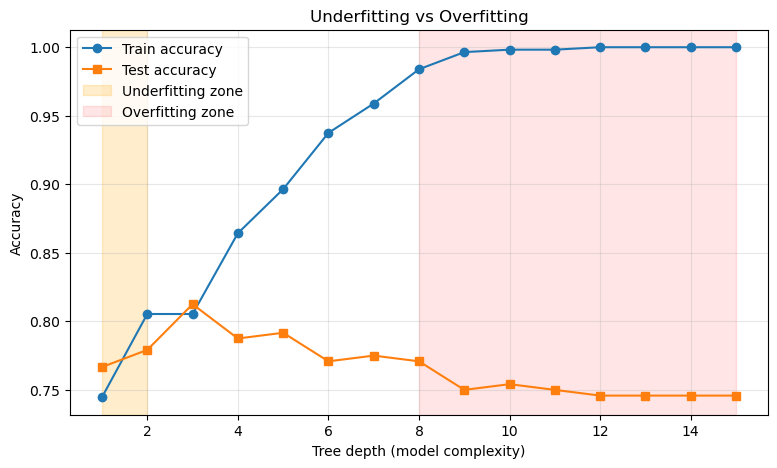

In [19]:
## Visualize both problems in one graph
depths = range(1, 16)
train_scores, test_scores = [], []

for d in depths:
    m = DecisionTreeClassifier(max_depth=d, random_state=42).fit(X_train, y_train)
    train_scores.append(m.score(X_train, y_train))
    test_scores.append(m.score(X_test, y_test))
plt.figure(figsize=(9, 5))
plt.plot(depths, train_scores, "o-", label="Train accuracy")
plt.plot(depths, test_scores, "s-", label="Test accuracy")
plt.axvspan(1, 2, color="orange", alpha=0.2, label="Underfitting zone")
plt.axvspan(8, 15, color="red", alpha=0.1, label="Overfitting zone")
plt.xlabel("Tree depth (model complexity)")
plt.ylabel("Accuracy")
plt.title("Underfitting vs Overfitting")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [21]:
## SOLUTION 1: Fix underfitting (make the model more capable)
fix_under = DecisionTreeClassifier(max_depth=3, random_state=42)
fix_under.fit(X_train, y_train)

print(f"FIXED UNDERFITTING -> Train: {fix_under.score(X_train, y_train):.3f} | "
      f"Test: {fix_under.score(X_test, y_test):.3f}")
## Train: 0.805 | Test: 0.812. Test accuracy rose from 0.767 to 0.812.

FIXED UNDERFITTING -> Train: 0.805 | Test: 0.812


In [23]:
## SOLUTION 2: Fix overfitting (limit the complexity)
param_grid = {
    "max_depth": range(2, 11),
    "min_samples_leaf": [1, 5, 10, 20],
    "ccp_alpha": [0, 0.005, 0.01],     # pruning strength
}
grid = GridSearchCV(DecisionTreeClassifier(random_state=42),
                    param_grid, cv=5, scoring="accuracy")
grid.fit(X_train, y_train)

best = grid.best_estimator_
print("Best parameters:", grid.best_params_)
print(f"FIXED OVERFITTING -> Train: {best.score(X_train, y_train):.3f} | "
      f"Test: {best.score(X_test, y_test):.3f} | "
      f"Gap: {best.score(X_train, y_train) - best.score(X_test, y_test):.3f}")
## Test accuracy rose from 0.746 to 0.800, and the train/test gap fell from 25.4% to 8.7%.

Best parameters: {'ccp_alpha': 0, 'max_depth': 7, 'min_samples_leaf': 10}
FIXED OVERFITTING -> Train: 0.887 | Test: 0.800 | Gap: 0.087


                      Model  Train Acc  Test Acc  CV Acc
0        Underfit (depth=1)      0.745     0.767   0.751
1        Overfit (no limit)      1.000     0.746   0.770
2  Fixed underfit (depth=3)      0.805     0.812   0.807
3     Fixed overfit (tuned)      0.888     0.800   0.810


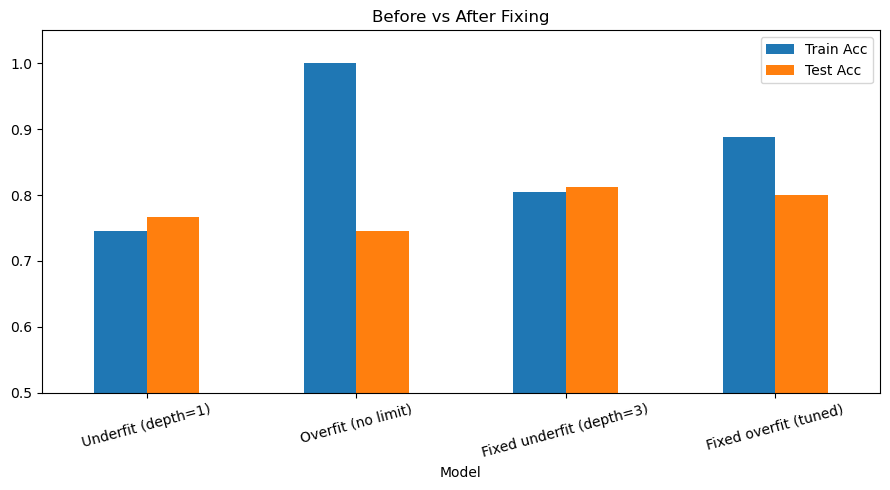

In [25]:
## Final comparison: before vs after
cv_under = cross_val_score(DecisionTreeClassifier(max_depth=1, random_state=42), X, y, cv=5).mean()
cv_over  = cross_val_score(DecisionTreeClassifier(random_state=42), X, y, cv=5).mean()
cv_fix_u = cross_val_score(DecisionTreeClassifier(max_depth=3, random_state=42), X, y, cv=5).mean()
cv_best  = cross_val_score(best, X, y, cv=5).mean()

results = pd.DataFrame({
    "Model": ["Underfit (depth=1)", "Overfit (no limit)",
              "Fixed underfit (depth=3)", "Fixed overfit (tuned)"],
    "Train Acc": [under.score(X_train, y_train), over.score(X_train, y_train),
                  fix_under.score(X_train, y_train), best.score(X_train, y_train)],
    "Test Acc":  [under.score(X_test, y_test), over.score(X_test, y_test),
                  fix_under.score(X_test, y_test), best.score(X_test, y_test)],
    "CV Acc":    [cv_under, cv_over, cv_fix_u, cv_best],
}).round(3)

print(results)

results.set_index("Model")[["Train Acc", "Test Acc"]].plot(kind="bar", figsize=(9, 5))
plt.ylim(0.5, 1.05)
plt.xticks(rotation=15)
plt.title("Before vs After Fixing")
plt.tight_layout()
plt.show()
## Both fixes bring test accuracy to about 0.80 to 0.81. 
## I can also show how dropping the 8 noise columns, 
## or switching to a Random Forest or Logistic Regression with regularization, changes the results.